# Case study: reading the explanations

Browse the explanations of one run of `scripts/run_explanations.py` in readable form (thresholds in original units, windows in seconds). Same functions as `scripts/case_study.py`, which writes the paper figures to `results/case_study/`.

In [1]:
import sys
sys.path.insert(0, "..")
sys.path.insert(0, "../scripts")
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from case_study import load_run, text, global_table, global_figure, instance_figure, atom_spans, _draw_atom, label
from stlrocket import instance_rules as ir

DATASET, RUN = "BasicMotions", 0
r = load_run(Path("../results/explanations"), DATASET, RUN)
print(f"{DATASET} run {RUN}: {len(r['S'])} formulae selected, classes {list(r['classes'])}")

BasicMotions run 0: 22 formulae selected, classes [np.str_('badminton'), np.str_('running'), np.str_('standing'), np.str_('walking')]


## Global explanations

In [2]:
out = Path("../results/case_study") / DATASET
out.parent.mkdir(exist_ok=True)
g = global_table(r, out)
g[["class", "rule", "precision_test", "coverage_test", "size"]]

,class,rule,precision_test,coverage_test,size
0,badminton,at some time in the whole series: acc_x > 25.2,0.888889,0.888889,3
1,running,at some time in the whole series: acc_x < -12.9,1.000000,1.000000,3
2,standing,"always in [5.7 s, the end]: gyr_z < 0.924",1.000000,0.900000,2
3,walking,"(at some time in [7.2 s, 9.9 s]: acc_y > 2.94)...",1.000000,0.818182,5


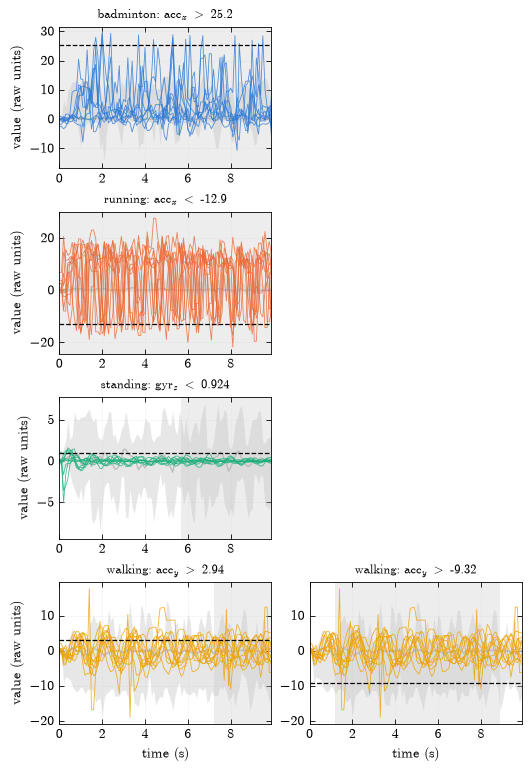

In [3]:
global_figure(r, out);

## Any test series

Change `I` to browse: the rule in readable form, its test metrics, and the series with the span and threshold of each atom.

test series 38: predicted walking, true badminton
rule: ((at some time in [0 s, 5.1 s]: (acc_y > 4.09) and (acc_x < 2.26)) and (at some time in [6.3 s, the end]: (acc_z > -2.25) and (acc_z < -1.95))) and (at some time in [1.4 s, 3.6 s]: always in [+3 s, +3.6 s]: acc_y > -0.0839)
test precision nan, coverage 0.000, train precision 1.000


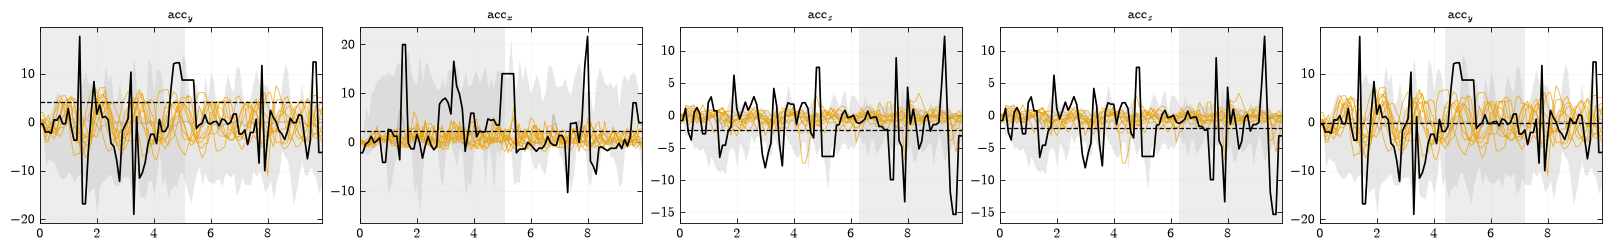

In [4]:
def show(i, split="test"):
    row = r["rules"][split].iloc[i]
    k = int(row.k)
    truth = r["classes"][r["true"][split][i]]
    print(f"{split} series {i}: predicted {r['classes'][k]}, true {truth}")
    if not row.literals:
        print("no rule")
        return
    phi = ir.rule_formula(row.literals, r["formulas"], r["sigma"], r["X"]["train"])
    print("rule:", text(r, phi))
    print(f"test precision {row.prec_test:.3f}, coverage {row.coverage_test:.3f}, train precision {row.prec_train:.3f}")
    spans = atom_spans(phi)
    fig, axes = plt.subplots(1, len(spans), figsize=(3.2 * len(spans), 2.4), squeeze=False, constrained_layout=True)
    for ax, (atom, a, b, neg) in zip(axes[0], spans):
        _draw_atom(ax, r, atom, a, b, k, split)
        v = atom.var_index
        ax.plot(np.arange(r["X_raw"][split].shape[2]) / r["info"].hz, r["X_raw"][split][i, v], color="black", linewidth=1.2)
        ax.set_title(label(r["info"].var_names[v]))
    plt.show()

I = 38
show(I)

## Instance explanations: why each literal favours the prediction

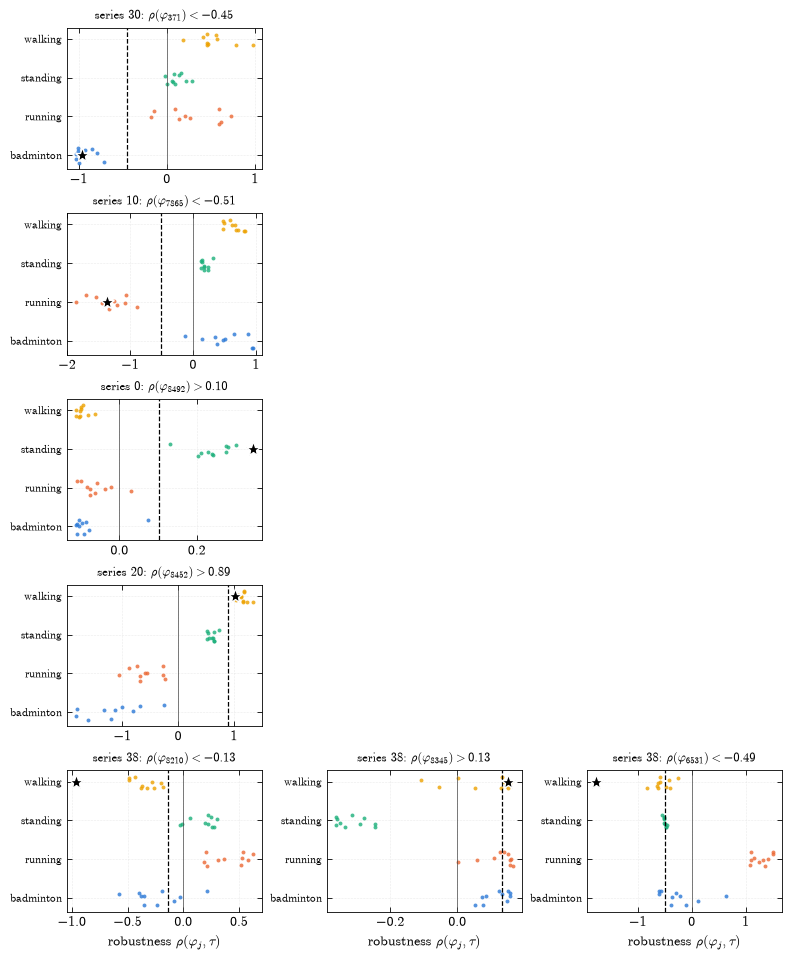

In [5]:
instance_figure(r, out);